In [33]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

In [6]:
# from tensorflow.keras import Sequential
%pip install tensorflow

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 1.3/351.2 MB 7.4 MB/s eta 0:00:48
   ---------------------------------------- 3.1/351.2 MB 7.9 MB/s eta 0:00:44
    --------------------------------------- 5.0/351.2 MB 7.9 MB/s eta 0:00:44
    --------------------------------------- 6.6/351.2 MB 7.9 MB/s eta 0:00:44
    --------------------------------------- 8.7/351.2 MB 8.1 MB/s eta 0:00:43
   - -------------------------------------- 10.2/351.2 MB 8.1 MB/s eta 0:00:43
   - -------------------------------------- 12.3/351.2 MB 8.3 MB/s eta 0:00:41
   - -------------------------------------- 14.2/351.2 MB 8.4 MB/s eta 0:00:41
   - -------------------------------------- 15.7/351.2 MB 8.3 MB/s eta 0:00:41
   -- ------------------------------------- 17.8/351.2 MB 8.3 MB/s eta 0:00:41
   -- ------------------------------------- 19.9/351.2 MB 8.5 MB/s eta 0:00:39
   -- ------------------------------------- 22.0/351.2 MB 8.6 MB/

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [10]:
# // import Packeages 
from tensorflow.keras import Sequential 

In [9]:
from tensorflow.keras.layers import Input, Flatten , Dense
from tensorflow.keras.optimizers import SGD

In [15]:
train_data = pd.read_csv('./MNIST(Ass2&3)/mnist_train.csv')
test_data = pd.read_csv('./MNIST(Ass2&3)/mnist_test.csv')

In [17]:
# Separate labels and images 

In [18]:
y_train = train_data.iloc[: , 0].values
y_test = test_data.iloc[: , 0 ].values
x_train = train_data.iloc[ : ,1 :].values
x_test = test_data.iloc[ : , 1 : ].values


In [19]:
print( "Training data shape : " , x_train.shape)
print( " testing data shape : " , x_test.shape) 

Training data shape :  (60000, 784)
 testing data shape :  (10000, 784)


In [20]:
#3 normalize the data 

In [21]:
x_train = x_train/ 255.0
x_test = x_test / 255.0


In [22]:
#Define the FNN Architecture 

In [23]:
model = Sequential([
    Input(shape=(784,)),
    Flatten(),
    Dense( 128 , activation='relu'),
    Dense( 64 , activation = 'relu'),
    Dense( 10 , activation='softmax')
])

In [24]:
#model Summary 
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
#compile the model using sgd 


In [27]:
model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [35]:
# step 6 Train the model using 11 eposchs
history = model.fit(
    x_train,
    y_train, 
    epochs=11,
    batch_size = 32 , 
    validation_split=0.2
)

Epoch 1/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9672 - loss: 0.1150 - val_accuracy: 0.9634 - val_loss: 0.1288
Epoch 2/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9694 - loss: 0.1078 - val_accuracy: 0.9636 - val_loss: 0.1268
Epoch 3/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9717 - loss: 0.1011 - val_accuracy: 0.9646 - val_loss: 0.1231
Epoch 4/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9735 - loss: 0.0948 - val_accuracy: 0.9652 - val_loss: 0.1205
Epoch 5/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9750 - loss: 0.0896 - val_accuracy: 0.9664 - val_loss: 0.1164
Epoch 6/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9764 - loss: 0.0843 - val_accuracy: 0.9674 - val_loss: 0.1151
Epoch 7/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9775 - loss: 0.0796 - val_accuracy: 0.9682 - val_loss: 0.1119
Epoch 8/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9790 - loss: 0.0752 - 

In [29]:
test_loss , test_accuracy  = model.evaluate(x_test , y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9606 - loss: 0.1322


In [30]:
print("loss : " , test_loss)
print("Accuaracy : " , test_accuracy )

loss :  0.1321994811296463
Accuaracy :  0.9606000185012817


In [31]:
# plot training loss and accuarcy 

In [34]:
plt.figure(figsize=(12,5))


<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

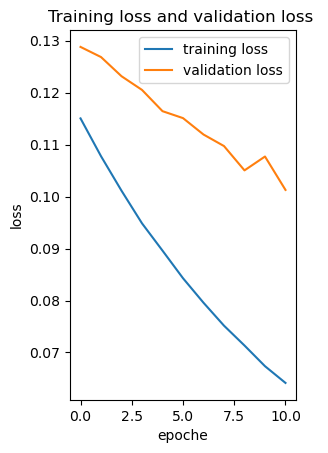

In [37]:
plt.subplot(1, 2,1 )
plt.plot(history.history['loss'] , label='training loss')
plt.plot( history.history['val_loss'] , label ='validation loss')
plt.title("Training loss and validation loss ")
plt.xlabel("epoche")
plt.ylabel("loss")
plt.legend()

In [38]:
#Plot Accuracy 

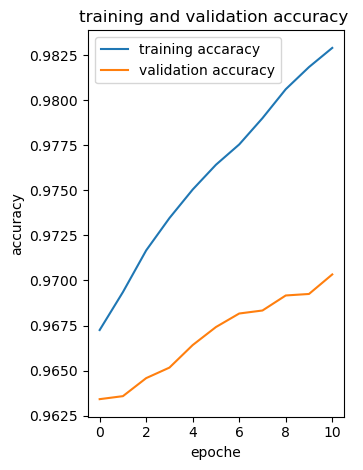

In [39]:
plt.subplot( 1 , 2,2 )
plt.plot( history.history['accuracy'] , label="training accaracy ")
plt.plot(history.history['val_accuracy'] , label="validation accuracy")
plt.title( "training and validation accuracy ")
plt.xlabel("epoche")
plt.ylabel("accuracy")
plt.legend()
plt.tight_layout()